In [1]:
import sys
import os

!nvcc --version
!which nvcc


nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2023 NVIDIA Corporation
Built on Mon_Apr__3_17:16:06_PDT_2023
Cuda compilation tools, release 12.1, V12.1.105
Build cuda_12.1.r12.1/compiler.32688072_0
/home/lesi-nedo/miniforge3/envs/HLT/bin/nvcc


In [ ]:
%%capture
!{sys.executable} -m pip install bitsandbytes
!{sys.executable} -m pip install -U -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!{sys.executable} -m pip install -U -q --no-deps "xformers<0.0.26" trl peft accelerate
!{sys.executable} -m pip install flash-attn --no-build-isolation


In [2]:
import re
import pandas as pd
import gc
import math
import numpy as np
from sklearn.metrics import (accuracy_score,
                             classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from datasets import Dataset
import bitsandbytes as bnb
from unsloth import FastLanguageModel
import torch
from tqdm import tqdm
from trl import SFTTrainer
from transformers import TrainingArguments, pipeline


/home/lesi-nedo/miniforge3/envs/HLT/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
try:
  from google.colab import drive
  drive.mount('/content/drive')
  dir = "/content/drive/MyDrive/HLT project/Project files/sentiment_annotated_with_texts.csv"
  txt_sent_sent = "/content/drive/MyDrive/HLT project/Project files/SentiWordNet_3.0.0.txt"
  txt_sent_vad = "/content/drive/MyDrive/HLT project/Project files/NRC-VAD-Lexicon.txt"

except ModuleNotFoundError:
  dir = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/sentiment_annotated_with_texts.csv"
  txt_sent_sent = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/SentiWordNet_3.0.0.txt"
  txt_sent_vad = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/NRC-VAD-Lexicon.txt"


In [4]:
def norm_text(data):
  return data.lower()
with open(dir, 'r') as f:
  df1 = pd.read_csv(f, delimiter=',', quotechar='"')

df = df1[['true_sentiment', 'text']]
del df1
df['text'] = df['text'].map(norm_text)
df[:5]

,true_sentiment,text
0,Positive,the euro was able to appreciate particularly s...
1,Positive,eur/chf yesterday broke above 1.00. economists...
2,Neutral,eur/chf vaults parity for the first time since...
3,Positive,eur/chf climbs back above parity. economists a...
4,Positive,eur/chf has broken out above the sideways rang...


In [ ]:
import gc
del model
gc.collect()
torch.cuda.empty_cache() # PyTorch thing
# from numba import cuda

# cuda.select_device(0) # choosing second GPU
# cuda.close()

In [5]:
torch.backends.cuda.enable_mem_efficient_sdp(False)
torch.backends.cuda.enable_flash_sdp(False)

In [6]:
X_train1 = list()
X_test1 = list()
test_perc = 0.20
val_perc = 0.0
train_perc = (1.0 - test_perc - val_perc)

df = df.sample(frac=1).reset_index(drop=True)


sentiments = ["Positive", "Neutral", "Negative"]
len_pos = len(df[df['true_sentiment'] == sentiments[0]])
len_neut = len(df[df['true_sentiment'] == sentiments[1]])
len_neg = len(df[df['true_sentiment'] == sentiments[2]])

size_split = {
    sentiments[0]: (int(len_pos * train_perc), int(len_pos * test_perc)),
    sentiments[1]: (int(len_neut * train_perc), int(len_neut * test_perc)),
    sentiments[2]: (int(len_neg * train_perc), int(len_neg * test_perc))
    }

for sent in sentiments:
  train, test = train_test_split(
      df[df['true_sentiment'] == sent],
      train_size=size_split[sent][0],
      test_size=size_split[sent][1],
      random_state=32,
  )
  X_train1.append(train)
  X_test1.append(test)

X_train1 = pd.concat(X_train1).sample(frac=1, random_state=56)
X_test1 = pd.concat(X_test1).sample(frac=1, random_state=42)


X_train1 = X_train1.reset_index(drop=True)
X_test1[:5]


,true_sentiment,text
1707,Neutral,theeur/usdrecovered from earlier losses that d...
1886,Positive,in january the swiss franc weakened versus the...
633,Negative,sellers seem in control of the sentiment aroun...
327,Neutral,eur/usd has extended its setback. economists a...
538,Neutral,theusd/jpy pairremains under some selling pres...


In [7]:

senti_word = {}
regex = '0(\.\d+)?\s0(\.\d+)?\s([a-z_\-]+#\d+\s)+'
pattern = re.compile(regex)


with open(txt_sent_sent, "r") as f:
  t = f.read()
  for si in t.split("\n"):
    if len(si) > 0 and si[0] != '#':
      matched = pattern.search(si)
      if matched:
        val = matched.group(0).split('\t')
        scor = [float(val[0]), float(val[1])]
        wors = re.split('#\d+\s?', val[2])
        wors.pop(-1)
        for wr in wors:
          senti_word[wr] = scor

df_senti = pd.DataFrame(senti_word, index=["pos_score", "negative_score"])
df_senti[:5]

,able,unable,dorsal,abaxial,ventral,adaxial,acroscopic,basiscopic,abducting,abducent,...,take_fire,conflagrate,catch_fire,flame_up,blaze_up,luminesce,shade_off,cloud_up,run_dry,fog_up
pos_score,0.25,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.000
negative_score,0.00,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0,0.125


In [8]:


data = {}

with open(txt_sent_vad, "r") as f:
  t = f.read()
  for si in t.split('\n'):
    si_w = (si +'\t').split('\t')
    if si_w[0] != '':
      data[si_w[0]] = list(map(lambda fl: float(fl), si_w[1:-1]))
    else:
      pass

for w,v in data.items():
  if len(v) < 3:
    print(w)

df2 = pd.DataFrame(data, index=['valence', 'arousal', 'dominance'])
df2[:5]

,aaaaaaah,aaaah,aardvark,aback,abacus,abalone,abandon,abandoned,abandonment,abashed,...,zit,zodiac,zombie,zone,zoning,zoo,zoological,zoology,zoom,zucchini
valence,0.479,0.520,0.427,0.385,0.510,0.500,0.052,0.046,0.128,0.177,...,0.337,0.594,0.214,0.531,0.417,0.76,0.667,0.568,0.490,0.510
arousal,0.606,0.636,0.490,0.407,0.276,0.480,0.519,0.481,0.430,0.644,...,0.410,0.429,0.648,0.349,0.400,0.52,0.458,0.347,0.520,0.321
dominance,0.291,0.282,0.437,0.288,0.485,0.412,0.245,0.130,0.202,0.307,...,0.381,0.426,0.415,0.382,0.578,0.58,0.492,0.509,0.462,0.250


In [9]:

max_seq_length = 2048
dtype = None
load_in_4bit = True
if  os.path.exists(f"{os.getcwd()}/llama-3-8b-Instruct-bnb-4bit"):
  model_name = f"{os.getcwd()}/llama-3-8b-Instruct-bnb-4bit"
else:
  model_name = "unsloth/llama-3-8b-Instruct-bnb-4bit"



fourbit_model = [
    "unsloth/llama-3-8b-Instruct-bnb-4bit",
]
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = model_name,
    use_cache=False,
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
    attn_implementation="flash_attention_2"
)

==((====))==  Unsloth: Fast Llama patching release 2024.4
   \\   /|    GPU: NVIDIA GeForce RTX 4080 Laptop GPU. Max memory: 11.721 GB. Platform = Linux.
O^O/ \_/ \    Pytorch: 2.3.0+cu121. CUDA = 8.9. CUDA Toolkit = 12.1.
\        /    Bfloat16 = TRUE. Xformers = 0.0.26.post1. FA = True.
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth


Loading checkpoint shards: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:10<00:00,  2.61s/it]
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [10]:
tokenizer.model_max_length = max_seq_length
tokenizer.pad_token = tokenizer.eos_token  # use unk rather than eos token to prevent endless generation
tokenizer.pad_token_id = tokenizer.convert_tokens_to_ids(tokenizer.pad_token)
tokenizer.padding_side = 'right'
tokenizer.truncation_side = "right"


In [11]:
if not os.path.exists(f"{os.getcwd()}/llama-3-8b-Instruct-bnb-4bit"):
    model.save_pretrained_merged(f"{os.getcwd()}/llama-3-8b-Instruct-bnb-4bit", tokenizer)

In [11]:
def predict(X_test, model, tokenizer):
  sent_reg = ".?([P,p]ositive|[N,n]egative|[N,n]eutral|[U,u]nclear)"

  y_pred = []
  for i in tqdm(range(len(X_test))):
    prompt = X_test.iloc[i]['text']
    pipe = pipeline(task="text-generation",
                    model=model,
                    tokenizer=tokenizer,
                    max_new_tokens=4,
                    temperature=0.0,
                    return_tensors="pt"
                    )

    result = pipe(prompt, pad_token_id=pipe.tokenizer.eos_token_id, return_full_text=False, do_sample=False)
    answer_match = re.findall(sent_reg, result[0]['generated_text'])
    if len(answer_match) == 1:
      answer = answer_match[0].lower()

      if "positive" in answer:
        y_pred.append("Positive")
      elif "negative" in answer:
        y_pred.append("Negative")
      elif "neutral" in answer:
        y_pred.append("Neutral")
      else:
        print(f"\nWeird match: {answer}")
        y_pred.append("Unclear")
    else:
      print(f"\nNot found: {result[0]}")
      y_pred.append("Unclear")
  return y_pred

In [12]:
def evaluate(y_true, y_pred):
  labels = [sent.lower() for sent in sentiments]
  mapping = {sentiments[0]: 2, sentiments[1]: 1, "Unclear": 1, sentiments[2]: 0}
  labels_map = {0: sentiments[2], 1: sentiments[1], 2: sentiments[0]}

  def map_func(x):
    return mapping.get(x, 1)

  y_true = np.vectorize(map_func)(y_true)
  y_pred = np.vectorize(map_func)(y_pred)

  accuracy = accuracy_score(y_true=y_true, y_pred=y_pred)
  print(f"Accuracy: {accuracy:.3f}")

  unique_labels = set(y_true)

  for label in unique_labels:
    label_indeces = [i for i in range(len(y_true))
                      if y_true[i] == label]
    label_y_true = [y_true[i] for i in label_indeces]
    label_y_pred = [y_pred[i] for i in label_indeces]
    accuracy = accuracy_score(label_y_true, label_y_pred)
    print(f"Accuracy for label {labels_map[label]}: {accuracy:.3f}")

  class_report = classification_report(y_true=y_true, y_pred=y_pred)
  print("\nClassification Report:")
  print(class_report)

  conf_matrix = confusion_matrix(y_true=y_true, y_pred=y_pred, labels=[0,1,2])
  print("\nConfusion Matrix:")
  disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=sentiments)
  disp.plot()

In [13]:

def get_sentiment_vad(text):
  text_split = text.split(" ")
  total_score = [0, 0, 0]
  added = 1
  for word in text_split:
    if word in df2:
      total_score[0] += df2[word]['valence']
      total_score[1] += df2[word]['arousal']
      total_score[2] += df2[word]['dominance']
      added += 1
  return np.array(total_score) / added

def get_sentiment(text):
  text_split = text.split(" ")
  total_score = [0, 0]
  added = 1
  for word in text_split:
    if word in df_senti:
      added += 1
      total_score[0] += df_senti[word]['pos_score']
      total_score[1] += df_senti[word]['negative_score']
  return np.array(total_score) / added

text = """Analyze the emotion sentence by sentence of the text enclosed in square brackets, determine if it is or positive, or neutral, or negative.
These values must be considered: valence score of text {:.5f}, arousal score of text {:.5f}, dominance score of text {:.5f}.
Take charge and empower yourself with the SentiWordNet Lexicon scores: positive {}, negative {}
It is imperative to keep in mind the direct correlation between the words.
\n\nThe sentiment of [{}] is
\n 'positive',
\n 'neutral',
\n 'negative'.
\n\nSolution: the correct option is""".strip()

def formatting_prompts_func(examples):
    all_words = set()
    score = get_sentiment(examples["text"])
    score_vad = get_sentiment_vad(examples["text"])


    return text.format(score_vad[0], score_vad[1], score_vad[2], score[0], -score[1], examples['text']) + " " +  f"'{examples['true_sentiment']}'"




def formatting_prompts_func_test(examples):

    all_words = set()


    score = get_sentiment(examples["text"])
    score_vad = get_sentiment_vad(examples["text"])


    return text.format( score_vad[0], score_vad[1], score_vad[2], score[0], -score[1], examples['text'])


#\n

torch.backends.cuda.enable_mem_efficient_sdp(False)
torch.backends.cuda.enable_flash_sdp(False)

X_train = pd.DataFrame(X_train1.apply(formatting_prompts_func, axis=1), columns=['text'])

y_true = X_test1.true_sentiment
X_test = pd.DataFrame(X_test1.apply(formatting_prompts_func_test, axis=1), columns=['text'])

train_data = Dataset.from_pandas(X_train)
len(train_data)

1832

In [14]:
X_train[:1]['text'].to_numpy()

array(["Analyze the emotion sentence by sentence of the text enclosed in square brackets, determine if it is or positive, or neutral, or negative. \nThese values must be considered: valence score of text 0.51636, arousal score of text 0.43374, dominance score of text 0.49513.\nTake charge and empower yourself with the SentiWordNet Lexicon scores: positive 0.05625, negative -0.07708333333333334\nIt is imperative to keep in mind the direct correlation between the words. \n\n\nThe sentiment of [in the opinion of economist lee sue ann and markets strategist quek ser leang at uob group,gbp/usdrisks a deeper pullback once 1.1950 is cleared. key quotes 24-hour view: “we did not anticipate the sharp rise in gbp to 1.1940 yesterday (we were expecting gbp to trade sideways). the advance lacks momentum and gbp is unlikely to strengthen much further. today, gbp is likely to trade between 1.1875 and 1.1950.’ next 1-3 weeks: “on wednesday (08 mar, spot at 1.1830), we indicated that gbp could weaken 

In [17]:
FastLanguageModel.for_inference(model)
y_pred = predict(X_test, model, tokenizer)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 457/457 [01:57<00:00,  3.88it/s]


Accuracy: 0.571
Accuracy for label Negative: 0.475
Accuracy for label Neutral: 0.448
Accuracy for label Positive: 0.791

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.48      0.57       141
           1       0.48      0.45      0.46       163
           2       0.57      0.79      0.66       153

    accuracy                           0.57       457
   macro avg       0.59      0.57      0.57       457
weighted avg       0.58      0.57      0.56       457


Confusion Matrix:


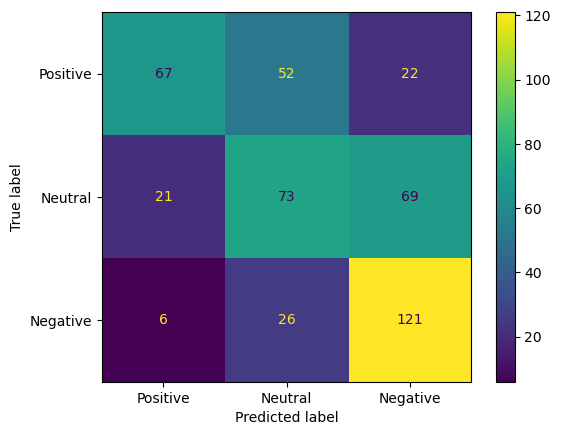

In [18]:
evaluate(y_true, y_pred)

In [15]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 32,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj",],

    lora_alpha = 32,
    lora_dropout = 0.0,
    bias = "none",
    use_gradient_checkpointing = True,
    random_state = 42,
    use_rslora = True,  # We support rank stabilized LoRA
    loftq_config = None, # And LoftQ
)

Unsloth 2024.4 patched 32 layers with 32 QKV layers, 32 O layers and 32 MLP layers.


In [17]:
training_config = {
    "do_eval": False,
    "do_train": True,
    "learning_rate": 2.0e-4,
    "adam_epsilon": 4.0e-7,
    "log_level": "info",
    "logging_steps": 10,
    "logging_strategy": "steps",
    "lr_scheduler_type": "linear",
    "num_train_epochs": 4,
    "max_steps": -1,
    "output_dir": "./checkpoint_dir",
    "overwrite_output_dir": True,
    "per_device_train_batch_size": 2,
    "gradient_accumulation_steps": 8,
    "save_steps": 100,
    "save_total_limit": 1,
    "gradient_checkpointing": True,
    "gradient_checkpointing_kwargs":{"use_reentrant": False},
    "warmup_ratio": 0.1,
    "fp16": not torch.cuda.is_bf16_supported(),
    "bf16": torch.cuda.is_bf16_supported(),
    "optim": "adamw_8bit",
    "weight_decay": 0.01,
    "seed": 42,
    "warmup_steps": 5,
    }

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_data,
    dataset_text_field = "text",
    max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False,
    args = TrainingArguments(
      **training_config
    ),
)
model.print_trainable_parameters()


PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
Both warmup_ratio and warmup_steps given, warmup_steps will override any effect of warmup_ratio during training
Map (num_proc=2): 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1832/1832 [00:01<00:00, 1632.30 examples/s]
Using auto half precision backend


trainable params: 83,886,080 || all params: 8,114,147,328 || trainable%: 1.0338249554642545


In [18]:
trainer_stats = trainer.train()

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs = 1
   \\   /|    Num examples = 1,832 | Num Epochs = 4
O^O/ \_/ \    Batch size per device = 2 | Gradient Accumulation steps = 8
\        /    Total batch size = 16 | Total steps = 456
 "-____-"     Number of trainable parameters = 83,886,080


Step,Training Loss
10,2.300400
20,1.652800
30,1.509600
40,1.410200
50,1.455900
60,1.408800
70,1.407200
80,1.403900
90,1.320300
100,1.303700


Saving model checkpoint to ./checkpoint_dir/checkpoint-100
/home/lesi-nedo/miniforge3/envs/HLT/lib/python3.11/site-packages/peft/utils/save_and_load.py:154: UserWarning: Could not find a config file in /home/lesi-nedo/llama-3-8b-Instruct-bnb-4bit - will assume that the vocabulary was not modified.
  warnings.warn(
tokenizer config file saved in ./checkpoint_dir/checkpoint-100/tokenizer_config.json
Special tokens file saved in ./checkpoint_dir/checkpoint-100/special_tokens_map.json
Deleting older checkpoint [checkpoint_dir/checkpoint-100] due to args.save_total_limit
Saving model checkpoint to ./checkpoint_dir/checkpoint-200
/home/lesi-nedo/miniforge3/envs/HLT/lib/python3.11/site-packages/peft/utils/save_and_load.py:154: UserWarning: Could not find a config file in /home/lesi-nedo/llama-3-8b-Instruct-bnb-4bit - will assume that the vocabulary was not modified.
  warnings.warn(
tokenizer config file saved in ./checkpoint_dir/checkpoint-200/tokenizer_config.json
Special tokens file saved 

In [19]:
metrics = trainer_stats.metrics
trainer.log_metrics("train", metrics)
trainer.save_metrics("train", metrics)
trainer.save_state()

***** train metrics *****
  epoch                    =      3.9825
  total_flos               = 195411792GF
  train_loss               =      0.8965
  train_runtime            =  1:17:05.44
  train_samples_per_second =       1.584
  train_steps_per_second   =       0.099


In [20]:
FastLanguageModel.for_inference(model)
y_pred = predict(X_test, model, tokenizer)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 457/457 [02:05<00:00,  3.63it/s]


Accuracy: 0.755
Accuracy for label Negative: 0.823
Accuracy for label Neutral: 0.632
Accuracy for label Positive: 0.824

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.82      0.81       141
           1       0.73      0.63      0.68       163
           2       0.75      0.82      0.78       153

    accuracy                           0.75       457
   macro avg       0.76      0.76      0.76       457
weighted avg       0.75      0.75      0.75       457


Confusion Matrix:


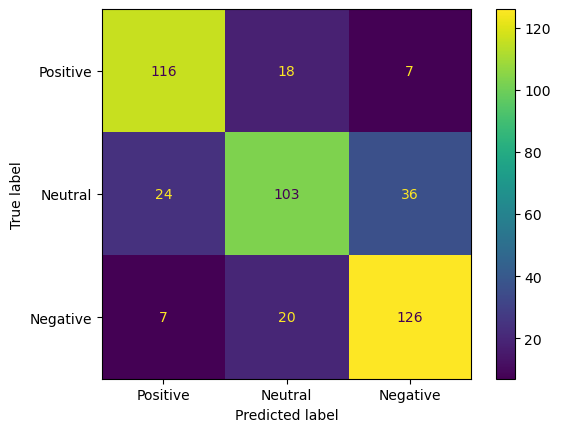

In [21]:
evaluate(y_true, y_pred)

In [22]:
model.save_pretrained_merged("llma3-model-fine-tuned", tokenizer)

Unsloth: Merging 4bit and LoRA weights to 16bit...
Unsloth: Will use up to 2.8 out of 14.83 RAM for saving.


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:12<00:00,  2.59it/s]
tokenizer config file saved in llma3-model-fine-tuned/tokenizer_config.json
Special tokens file saved in llma3-model-fine-tuned/special_tokens_map.json
Model config LlamaConfig {
  "_name_or_path": "/home/lesi-nedo/llama-3-8b-Instruct-bnb-4bit",
  "architectures": [
    "LlamaForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": 128000,
  "eos_token_id": 128001,
  "hidden_act": "silu",
  "hidden_size": 4096,
  "initializer_range": 0.02,
  "intermediate_size": 14336,
  "max_position_embeddings": 8192,
  "mlp_bias": false,
  "model_type": "llama",
  "num_attention_heads": 32,
  "num_hidden_layers": 32,
  "num_key_value_heads": 8,
  "pretraining_tp": 1,
  "rms_norm_eps": 1e-05,
  "rope_scaling": null,
  "rope_theta": 500000.0,


Unsloth: Saving tokenizer... Done.
Unsloth: Saving model... This might take 5 minutes for Llama-7b...


The model is bigger than the maximum size per checkpoint (5GB) and is going to be split in 4 checkpoint shards. You can find where each parameters has been saved in the index located at llma3-model-fine-tuned/model.safetensors.index.json.


Done.
